# Comparing Backpropagation and Predictive Coding for House-Value Regression

I built this notebook to compare two supervised neural-network approaches on the same house-value regression task. I first train a feedforward PyTorch network using backpropagation, then implement a predictive-coding (PC) variant with explicit layer-wise prediction errors, energy terms, and iterative hidden-state inference.

I use the Kaggle dataset `hosammhmdali/house-price-dataset` and predict `median_house_value` from the available housing attributes. The core supervised learning problem is:

$$
\hat{y}_i = f_{\theta}(x_i), \quad x_i \in \mathbb{R}^d, \; y_i \in \mathbb{R}
$$

where $x_i$ is the feature vector for observation $i$, $y_i$ is the target price, and $\theta$ collects the learnable parameters. The notebook compares two parameterizations of $f_{\theta}$ and evaluates them on a held-out test partition.


## 1. The task and dataset I use

I treat `median_house_value` as a continuous regression target. The dataset is the California housing data: each row describes a census block group using geographic, demographic, and housing-related attributes. The expected fields include longitude and latitude, housing age, room and population counts, median income, the target, and the categorical `ocean_proximity` feature.

The target is continuous, so the learning problem is a regression task rather than a classification task. In a regression setting, the model learns a mapping from inputs to a real-valued prediction:

$$
\mathcal{D} = \{(x_i, y_i)\}_{i=1}^n, \qquad \hat{y}_i = f_{\theta}(x_i), \qquad y_i \in \mathbb{R}
$$

The notebook then evaluates how well $f_{\theta}$ predicts unseen house values from the same feature distribution.


## 2. How I prepare the data

I represent each example as a feature vector $(x_i)$ and a target $(y_i)$. I split the data before fitting preprocessing so that the held-out test set does not contribute to imputation, category encoding, or scaling. This keeps the estimate of model performance honest and prevents information leakage from the test partition into the training pipeline.

The standard data-preparation workflow is:

$$
(x_i, y_i) \xrightarrow[]{\text{split}} (X_{\text{train}}, y_{\text{train}}), (X_{\text{test}}, y_{\text{test}})
$$

and then

$$
\tilde{x}_i = g(X_{\text{train}}; x_i), \qquad \tilde{y}_i = y_i
$$

where $g(\cdot)$ denotes the fitted preprocessing transform (imputation, one-hot encoding, and scaling). The trained model is then optimized only on the transformed training data.


In [1]:


from pathlib import Path
import os
import random
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("Device:", DEVICE)

PyTorch: 2.14.1+cu130
Device: cpu


## 3. Downloading and inspecting the dataset

I download the dataset using the KaggleHub identifier supplied for this project. Because KaggleHub returns a directory rather than a CSV path, I search recursively for CSV files and print their shapes and columns. This lets me verify what I actually downloaded before selecting the regression table.

In [2]:
import kagglehub

dataset_path = kagglehub.dataset_download("hosammhmdali/house-price-dataset")
dataset_dir = Path(dataset_path)

print("Dataset directory:", dataset_dir)
csv_files = sorted(dataset_dir.rglob("*.csv"))
if not csv_files:
    raise FileNotFoundError(
        f"No CSV files found under {dataset_dir}. Inspect the downloaded dataset contents."
    )

for i, csv_path in enumerate(csv_files, start=1):
    preview = pd.read_csv(csv_path, nrows=5)
    print(f"\\n[{i}] {csv_path.name}")
    print("Preview shape (first 5 rows):", preview.shape)
    print("Columns:", preview.columns.tolist())
    display(preview.head(3))

/home/solomon/Desktop/backprop-pc/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Dataset directory: /home/solomon/.cache/kagglehub/datasets/hosammhmdali/house-price-dataset/versions/1
\n[1] housing.csv
Preview shape (first 5 rows): (5, 10)
Columns: ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'median_house_value', 'ocean_proximity']


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY


### Selecting the regression table

I use `median_house_value` as the expected target. If there is only one CSV, the code selects it; if there are several, it selects a file containing the target column. If none contains the target, the code raises an error rather than silently training on the wrong table.

In [3]:
TARGET = "median_house_value"

candidate_frames = []
for csv_path in csv_files:
    frame = pd.read_csv(csv_path)
    # Normalize accidental whitespace in column labels without changing values.
    frame.columns = frame.columns.astype(str).str.strip()
    if TARGET in frame.columns:
        candidate_frames.append((csv_path, frame))

if not candidate_frames:
    raise ValueError(
        f"Could not find target column '{TARGET}' in the downloaded CSV files. "
        f"Review the printed columns and update TARGET to the dataset's actual target."
    )

data_path, df = candidate_frames[0]
print("Selected file:", data_path.name)
print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())

Selected file: housing.csv
Dataset shape: (20640, 10)
Columns: ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'median_house_value', 'ocean_proximity']


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


## 4. Checking data quality and defining features

I separate the target from the predictors and remove rows with missing target values, since those rows cannot provide supervised examples. I exclude clearly named ID or unnamed index columns, then identify numeric and categorical predictors from their actual data types. That lets me encode `ocean_proximity` as a category rather than treating its labels as numbers.

For missing predictors, I fit a median imputer for numeric columns and a most-frequent-value imputer for categorical columns using training data only. I use the median because it is less sensitive to skew and outliers than the mean.

In [4]:
df = df.copy()
df = df.dropna(subset=[TARGET])

# Remove accidental index columns if present; do not remove meaningful predictors.
drop_cols = [
    c for c in df.columns
    if c.lower().startswith("unnamed:") or c.lower() in {"id", "index"}
]
if drop_cols:
    print("Dropping index/identifier columns:", drop_cols)
    df = df.drop(columns=drop_cols)

X = df.drop(columns=[TARGET])
y = pd.to_numeric(df[TARGET], errors="coerce")
valid_target = y.notna()
X = X.loc[valid_target].copy()
y = y.loc[valid_target].astype(float)

numeric_features = X.select_dtypes(include=["number", "bool"]).columns.tolist()
categorical_features = X.select_dtypes(exclude=["number", "bool"]).columns.tolist()

print("Rows:", len(X))
print("Numeric predictors:", numeric_features)
print("Categorical predictors:", categorical_features)
print("Missing target values after cleaning:", int(y.isna().sum()))
print("Target summary:")
display(y.describe().to_frame("median_house_value"))

Rows: 20640
Numeric predictors: ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income']
Categorical predictors: ['ocean_proximity']
Missing target values after cleaning: 0
Target summary:


,median_house_value
count,20640.000000
mean,206855.816909
std,115395.615874
min,14999.000000
25%,119600.000000
50%,179700.000000
75%,264725.000000
max,500001.000000


## 5. Splitting the data and fitting preprocessing

I reserve 20% of the observations for the final test evaluation and use a seeded split for reproducibility. I fit preprocessing on the training partition only. I one-hot encode categorical values so the model does not interpret category labels as an ordered scale, and scale the resulting features for optimization.

The result is a numeric feature matrix that I can pass to PyTorch. The target is standardized using training-set statistics and later converted back to house-value units for evaluation.

In [5]:
X_train_raw, X_test_raw, y_train_raw, y_test_raw = train_test_split(
    X, y, test_size=0.20, random_state=SEED
)

numeric_pipe = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipe = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

transformers = []
if numeric_features:
    transformers.append(("numeric", numeric_pipe, numeric_features))
if categorical_features:
    transformers.append(("categorical", categorical_pipe, categorical_features))

preprocessor = ColumnTransformer(transformers=transformers, remainder="drop")

X_train_np = preprocessor.fit_transform(X_train_raw).astype(np.float32)
X_test_np = preprocessor.transform(X_test_raw).astype(np.float32)

# Standardize the target using training data only.
y_mean = float(y_train_raw.mean())
y_std = float(y_train_raw.std(ddof=0))
if not np.isfinite(y_std) or y_std == 0:
    y_std = 1.0

y_train_np = ((y_train_raw.to_numpy(dtype=np.float32) - y_mean) / y_std).reshape(-1, 1)
y_test_np = ((y_test_raw.to_numpy(dtype=np.float32) - y_mean) / y_std).reshape(-1, 1)

X_train_t = torch.tensor(X_train_np, dtype=torch.float32)
X_test_t = torch.tensor(X_test_np, dtype=torch.float32)
y_train_t = torch.tensor(y_train_np, dtype=torch.float32)
y_test_t = torch.tensor(y_test_np, dtype=torch.float32)

print("Processed training matrix:", X_train_t.shape)
print("Processed test matrix:", X_test_t.shape)
print("Target mean / std (training only):", y_mean, "/", y_std)

Processed training matrix: torch.Size([16512, 13])
Processed test matrix: torch.Size([4128, 13])
Target mean / std (training only): 207194.6937378876 / 115619.12522543264


## 6. Metrics I use for evaluation

I report mean absolute error (MAE), root mean squared error (RMSE), and $R^2$ on the held-out data, after converting predictions to the target's original units.

These metrics are defined as:

$$
\text{MAE} = \frac{1}{n}\sum_{i=1}^n |\hat{y}_i - y_i|
$$

$$
\text{RMSE} = \sqrt{\frac{1}{n}\sum_{i=1}^n (\hat{y}_i - y_i)^2}
$$

$$
R^2 = 1 - \frac{\sum_{i=1}^n (\hat{y}_i - y_i)^2}{\sum_{i=1}^n (y_i - \bar{y})^2}
$$

Lower MAE and RMSE are better, while higher $R^2$ is better. I use these to compare the backpropagation and predictive-coding models on the same test examples.


In [6]:
def evaluate_predictions(y_true_original, y_pred_standardized):
    y_pred_original = np.asarray(y_pred_standardized).reshape(-1) * y_std + y_mean
    y_true_original = np.asarray(y_true_original).reshape(-1)
    return {
        "MAE": mean_absolute_error(y_true_original, y_pred_original),
        "RMSE": mean_squared_error(y_true_original, y_pred_original) ** 0.5,
        "R2": r2_score(y_true_original, y_pred_original),
    }, y_pred_original

def make_loader(X_tensor, y_tensor, batch_size=256, shuffle=True):
    return DataLoader(
        TensorDataset(X_tensor, y_tensor),
        batch_size=batch_size,
        shuffle=shuffle,
        drop_last=False
    )

# Part A — My backpropagation model

## 7. Forward pass and training objective

I use a feedforward network with two hidden layers of 64 and 32 units. Each hidden layer applies an affine map followed by a nonlinear activation. The model transforms the input feature vector into a scalar prediction through:

$$
h_1 = \phi(W_1 x + b_1), \quad h_2 = \phi(W_2 h_1 + b_2), \quad \hat{y} = W_3 h_2 + b_3
$$

where $\phi(\cdot)$ is a nonlinear activation, $W_\ell$ are weight matrices, and $b_\ell$ are biases. The training objective is the mean squared error (MSE):

$$
\mathcal{L}(\theta) = \frac{1}{n}\sum_{i=1}^n (\hat{y}_i - y_i)^2
$$

I minimize this loss with a standard optimizer, and the backward pass propagates the gradient of the loss with respect to each parameter.


In [7]:
class BackpropRegressor(nn.Module):
    def __init__(self, input_dim, hidden1=64, hidden2=32):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(input_dim, hidden1),
            nn.Tanh(),
            nn.Linear(hidden1, hidden2),
            nn.Tanh(),
            nn.Linear(hidden2, 1)
        )

    def forward(self, x):
        return self.layers(x)

input_dim = X_train_t.shape[1]
bp_model = BackpropRegressor(input_dim).to(DEVICE)
print(bp_model)
print("Trainable parameters:", sum(p.numel() for p in bp_model.parameters() if p.requires_grad))

BackpropRegressor(
  (layers): Sequential(
    (0): Linear(in_features=13, out_features=64, bias=True)
    (1): Tanh()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): Tanh()
    (4): Linear(in_features=32, out_features=1, bias=True)
  )
)
Trainable parameters: 3009


### Why I use nonlinear hidden layers

If I stack linear maps without nonlinear activations, the composition is still a single linear map, so adding layers alone does not let the network represent more complex relationships. The key idea is to alternate affine transforms with nonlinearities:

$$
h_\ell = \phi(W_\ell h_{\ell-1} + b_\ell)
$$

If $\phi$ were linear, then

$$
W_3 \phi(W_2 \phi(W_1 x + b_1) + b_2) + b_3
$$

would reduce to a single equivalent linear transform. Nonlinearity is what allows the network to capture curvature and interactions between features in the housing data.


In [8]:
def train_backprop(model, X_train, y_train, epochs=60, batch_size=256, lr=1e-3):
    loader = make_loader(X_train, y_train, batch_size=batch_size, shuffle=True)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.MSELoss()
    history = []

    model.train()
    for epoch in range(epochs):
        batch_losses = []
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            optimizer.zero_grad()
            pred = model(xb)
            loss = loss_fn(pred, yb)
            loss.backward()       # Chain rule: dL/dtheta for all parameters.
            optimizer.step()      # theta <- theta - learning_rate * gradient
            batch_losses.append(loss.item())

        history.append(float(np.mean(batch_losses)))
        if (epoch + 1) % 10 == 0 or epoch == 0:
            print(f"Epoch {epoch+1:>3}/{epochs} | standardized MSE: {history[-1]:.5f}")
    return history

bp_history = train_backprop(
    bp_model, X_train_t, y_train_t, epochs=60, batch_size=256, lr=1e-3
)

Epoch   1/60 | standardized MSE: 0.49978
Epoch  10/60 | standardized MSE: 0.27071
Epoch  20/60 | standardized MSE: 0.25305
Epoch  30/60 | standardized MSE: 0.24514
Epoch  40/60 | standardized MSE: 0.23743
Epoch  50/60 | standardized MSE: 0.23102
Epoch  60/60 | standardized MSE: 0.22589


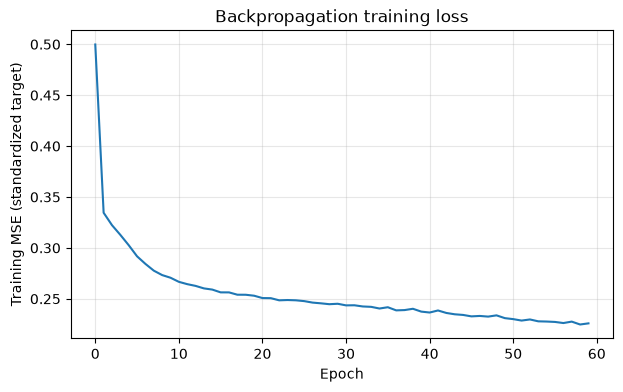

In [9]:
plt.figure(figsize=(7, 4))
plt.plot(bp_history)
plt.xlabel("Epoch")
plt.ylabel("Training MSE (standardized target)")
plt.title("Backpropagation training loss")
plt.grid(True, alpha=0.3)
plt.show()

## 8. Inspecting the backpropagation prediction

After training, I evaluate the network on the test partition. I use test loss only for reporting; it does not affect parameter updates. Keeping the test data out of training gives me a more honest estimate of performance on unseen observations.

In [10]:
bp_model.eval()
with torch.no_grad():
    bp_test_pred_z = bp_model(X_test_t.to(DEVICE)).cpu().numpy()

bp_metrics, bp_pred_original = evaluate_predictions(y_test_raw.to_numpy(), bp_test_pred_z)
print("Backpropagation test metrics:")
for name, value in bp_metrics.items():
    print(f"{name}: {value:,.4f}")

Backpropagation test metrics:
MAE: 38,755.0999
RMSE: 57,255.4619
R2: 0.7498


# Part B — My predictive-coding model

## 9. The predictive-coding formulation I implement

In the predictive-coding (PC) model, hidden states are not just intermediate activations; they are latent variables that are repeatedly adjusted to minimize an energy function. A compact way to express the model is:

$$
E(z; x, y) = \sum_{\ell=1}^{L} \|z_\ell - W_\ell z_{\ell-1}\|^2 + \|y - W_{out} z_L\|^2
$$

where $z_\ell$ is the latent state at layer $\ell$, $x$ is the input, and $y$ is the target. The network tries to find latent states that make each layer predict the next one and the final latent representation predict the target value.

This is different from ordinary feedforward inference, because the hidden values are not computed once and discarded; they are iteratively updated to reduce the energy.


## 10. Why I update latent states

In a standard feedforward pass, each hidden activation is computed once from the preceding layer. In my PC implementation, the hidden states are variables in the energy function, so I compute them by minimizing the total energy. The update rule is a gradient-descent step:

$$
z_\ell^{(t+1)} = z_\ell^{(t)} - \eta\,\frac{\partial E}{\partial z_\ell}
$$

where $\eta$ is the step size and $t$ indexes the inference iterations. This makes each latent state a stable estimate of the belief that best matches the input and target given the model parameters. In effect, the network searches for a consistent internal representation before producing the output prediction.


In [11]:
class PredictiveCodingRegressor(nn.Module):
    def __init__(self, input_dim, hidden1=64, hidden2=32):
        super().__init__()
        self.W1 = nn.Linear(input_dim, hidden1)
        self.W2 = nn.Linear(hidden1, hidden2)
        self.W3 = nn.Linear(hidden2, 1)

    def initialize_states(self, x):
        # Initial states use a forward projection, then PC inference may revise them.
        z1 = torch.tanh(self.W1(x))
        z2 = torch.tanh(self.W2(z1))
        return z1, z2

    def predict_from_states(self, z2):
        return self.W3(z2)

    def forward(self, x):
        z1, z2 = self.initialize_states(x)
        return self.predict_from_states(z2)

    def layer_energies(self, x, y, z1, z2):
        mu1 = torch.tanh(self.W1(x))
        mu2 = torch.tanh(self.W2(z1))
        mu3 = self.W3(z2)

        # Sum squared error across units, then average over examples.
        E1 = 0.5 * ((z1 - mu1) ** 2).sum(dim=1).mean()
        E2 = 0.5 * ((z2 - mu2) ** 2).sum(dim=1).mean()
        E3 = 0.5 * ((y - mu3) ** 2).sum(dim=1).mean()
        E_total = E1 + E2 + E3
        return {"E1": E1, "E2": E2, "E3": E3, "E_total": E_total}

### What the layer energies measure

- The first energy penalizes disagreement between the first latent state and its prediction from the observed input.
- The middle layer energy penalizes inconsistency between adjacent latent representations.
- The final latent contribution reflects how well the deeper hidden state predicts the next layer and ultimately the output.

I can write these layer-wise terms as:

$$
E_1 = \|x - W_1 z_1\|^2,\quad E_2 = \|z_1 - W_2 z_2\|^2,\quad E_3 = \|z_2 - W_3 z_3\|^2
$$

and the overall inference objective is the sum of these contributions plus the output mismatch:

$$
E_{\text{total}} = E_1 + E_2 + E_3 + \|y - \hat{y}\|^2
$$

This decomposition helps explain whether the model is failing because the input is poorly reconstructed, the hidden representation is inconsistent, or the output prediction is inaccurate.


## 11. How I train the PC model

I compare 1, 3, 5, and 10 latent-state inference steps using a validation fold taken from the training partition. For each count, I train an otherwise-matched model for 20 epochs and record the validation error. I then choose the inference-step count that minimizes validation RMSE:

$$
\text{steps}^* = \arg\min_{s \in \{1,3,5,10\}} \text{RMSE}(s)
$$

The sweep is therefore a small hyperparameter search over the inference procedure itself, not just over the optimizer or architecture. It tells us whether more iterative state updates improve generalization for this regression task.


In [12]:
def train_predictive_coding(
    model, X_train, y_train, epochs=60, batch_size=256,
    lr_theta=1e-3, lr_state=0.05, inference_steps=5
):
    loader = make_loader(X_train, y_train, batch_size=batch_size, shuffle=True)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr_theta)
    history = []
    energy_history = []

    for epoch in range(epochs):
        batch_totals = []
        batch_layers = []

        model.train()
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)

            # State initialization from current predictions.
            with torch.no_grad():
                z1_init, z2_init = model.initialize_states(xb)
            z1 = z1_init.detach().requires_grad_(True)
            z2 = z2_init.detach().requires_grad_(True)

            # Inference: minimize E with respect to latent states.
            for _ in range(inference_steps):
                energies = model.layer_energies(xb, yb, z1, z2)
                grad_z1, grad_z2 = torch.autograd.grad(
                    energies["E_total"], (z1, z2), retain_graph=False
                )
                with torch.no_grad():
                    z1 = (z1 - lr_state * grad_z1).detach().requires_grad_(True)
                    z2 = (z2 - lr_state * grad_z2).detach().requires_grad_(True)

            # Learning: update weights and biases from the energy gradient.
            optimizer.zero_grad()
            energies = model.layer_energies(xb, yb, z1, z2)
            energies["E_total"].backward()
            optimizer.step()

            batch_totals.append(float(energies["E_total"].detach().cpu()))
            batch_layers.append([
                float(energies["E1"].detach().cpu()),
                float(energies["E2"].detach().cpu()),
                float(energies["E3"].detach().cpu())
            ])

        history.append(float(np.mean(batch_totals)))
        energy_history.append(np.mean(batch_layers, axis=0).tolist())

        if (epoch + 1) % 10 == 0 or epoch == 0:
            e1, e2, e3 = energy_history[-1]
            print(
                f"Epoch {epoch+1:>3}/{epochs} | "
                f"E1={e1:.5f}, E2={e2:.5f}, E3={e3:.5f}, "
                f"total={history[-1]:.5f}"
            )

    return history, np.asarray(energy_history)

### Why I update more than the output layer

The output error indicates that the final prediction is wrong, but the hidden states determine the representation used to produce that prediction. In my PC formulation, the output error can influence the second latent state, which can in turn influence the first, through the total-energy gradients. If I kept the hidden states fixed, I would remove a defining part of this PC procedure and move closer to fitting parameters over a fixed feedforward path.

In [13]:
X_sweep_train_raw, X_sweep_val_raw, y_sweep_train_raw, y_sweep_val_raw = train_test_split(
    X_train_raw, y_train_raw, test_size=0.15, random_state=SEED
)

sweep_preprocessor = clone(preprocessor)
X_sweep_train_np = sweep_preprocessor.fit_transform(X_sweep_train_raw).astype(np.float32)
X_sweep_val_np = sweep_preprocessor.transform(X_sweep_val_raw).astype(np.float32)
sweep_y_mean = float(y_sweep_train_raw.mean())
sweep_y_std = float(y_sweep_train_raw.std(ddof=0))
if not np.isfinite(sweep_y_std) or sweep_y_std == 0:
    sweep_y_std = 1.0

y_sweep_train_np = (
    (y_sweep_train_raw.to_numpy(dtype=np.float32) - sweep_y_mean) / sweep_y_std
).reshape(-1, 1)
y_sweep_val_np = (
    (y_sweep_val_raw.to_numpy(dtype=np.float32) - sweep_y_mean) / sweep_y_std
).reshape(-1, 1)

X_sweep_train_t = torch.tensor(X_sweep_train_np, dtype=torch.float32)
X_sweep_val_t = torch.tensor(X_sweep_val_np, dtype=torch.float32)
y_sweep_train_t = torch.tensor(y_sweep_train_np, dtype=torch.float32)
y_sweep_val_t = torch.tensor(y_sweep_val_np, dtype=torch.float32)

inference_step_options = [1, 3, 5, 10]
sweep_records = []
for steps in inference_step_options:
    torch.manual_seed(SEED)
    if DEVICE.type == "cuda":
        torch.cuda.manual_seed_all(SEED)

    trial_model = PredictiveCodingRegressor(X_sweep_train_t.shape[1]).to(DEVICE)
    started_at = time.perf_counter()
    train_predictive_coding(
        trial_model,
        X_sweep_train_t,
        y_sweep_train_t,
        epochs=20,
        batch_size=256,
        lr_theta=1e-3,
        lr_state=0.05,
        inference_steps=steps
    )
    training_seconds = time.perf_counter() - started_at

    trial_model.eval()
    with torch.no_grad():
        val_pred_z = trial_model(X_sweep_val_t.to(DEVICE)).cpu().numpy().reshape(-1)
    val_pred = val_pred_z * sweep_y_std + sweep_y_mean
    val_true = y_sweep_val_raw.to_numpy()
    sweep_records.append({
        "Inference steps": steps,
        "Validation MAE": mean_absolute_error(val_true, val_pred),
        "Validation RMSE": mean_squared_error(val_true, val_pred) ** 0.5,
        "Validation R2": r2_score(val_true, val_pred),
        "20-epoch training seconds": training_seconds
    })

sweep_results = pd.DataFrame(sweep_records)
selected_inference_steps = int(
    sweep_results.loc[sweep_results["Validation RMSE"].idxmin(), "Inference steps"]
)
display(sweep_results.style.format({
    "Validation MAE": "{:,.2f}",
    "Validation RMSE": "{:,.2f}",
    "Validation R2": "{:.4f}",
    "20-epoch training seconds": "{:.1f}"
}))
print(f"Selected inference steps from validation RMSE: {selected_inference_steps}")

# Retrain the selected configuration on all training examples; the test set stays untouched.
torch.manual_seed(SEED)
if DEVICE.type == "cuda":
    torch.cuda.manual_seed_all(SEED)
pc_model = PredictiveCodingRegressor(input_dim).to(DEVICE)
pc_history, pc_energy_history = train_predictive_coding(
    pc_model,
    X_train_t,
    y_train_t,
    epochs=60,
    batch_size=256,
    lr_theta=1e-3,
    lr_state=0.05,
    inference_steps=selected_inference_steps
)

Epoch   1/20 | E1=0.00000, E2=0.00000, E3=0.28685, total=0.28685
Epoch  10/20 | E1=0.00000, E2=0.00000, E3=0.15081, total=0.15081
Epoch  20/20 | E1=0.00000, E2=0.00000, E3=0.13424, total=0.13424
Epoch   1/20 | E1=0.00000, E2=0.00000, E3=0.28549, total=0.28549
Epoch  10/20 | E1=0.00000, E2=0.00000, E3=0.14964, total=0.14964
Epoch  20/20 | E1=0.00000, E2=0.00000, E3=0.13323, total=0.13323
Epoch   1/20 | E1=0.00000, E2=0.00000, E3=0.28268, total=0.28269
Epoch  10/20 | E1=0.00000, E2=0.00000, E3=0.14761, total=0.14761
Epoch  20/20 | E1=0.00000, E2=0.00000, E3=0.13225, total=0.13225
Epoch   1/20 | E1=0.00000, E2=0.00000, E3=0.27508, total=0.27508
Epoch  10/20 | E1=0.00000, E2=0.00000, E3=0.14306, total=0.14306
Epoch  20/20 | E1=0.00000, E2=0.00000, E3=0.12980, total=0.12980


,Inference steps,Validation MAE,Validation RMSE,Validation R2,20-epoch training seconds
0,1,"44,035.88","62,067.04",0.7214,7.5
1,3,"43,886.42","61,930.24",0.7226,6.5
2,5,"43,780.77","61,862.10",0.7232,7.2
3,10,"43,345.11","61,578.93",0.7257,18.2


Selected inference steps from validation RMSE: 10
Epoch   1/60 | E1=0.00000, E2=0.00000, E3=0.26041, total=0.26041
Epoch  10/60 | E1=0.00000, E2=0.00000, E3=0.14037, total=0.14037
Epoch  20/60 | E1=0.00000, E2=0.00000, E3=0.12936, total=0.12936
Epoch  30/60 | E1=0.00000, E2=0.00000, E3=0.12439, total=0.12439
Epoch  40/60 | E1=0.00000, E2=0.00000, E3=0.12103, total=0.12103
Epoch  50/60 | E1=0.00000, E2=0.00000, E3=0.11841, total=0.11841
Epoch  60/60 | E1=0.00000, E2=0.00000, E3=0.11629, total=0.11629


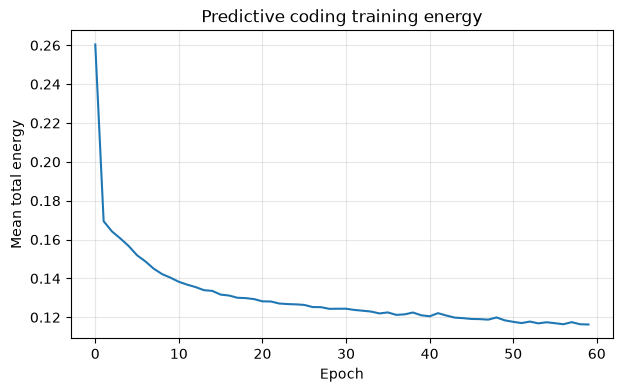

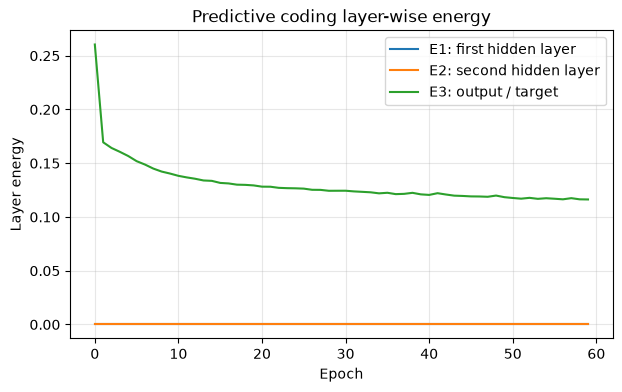

In [14]:
plt.figure(figsize=(7, 4))
plt.plot(pc_history)
plt.xlabel("Epoch")
plt.ylabel("Mean total energy")
plt.title("Predictive coding training energy")
plt.grid(True, alpha=0.3)
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(pc_energy_history[:, 0], label="E1: first hidden layer")
plt.plot(pc_energy_history[:, 1], label="E2: second hidden layer")
plt.plot(pc_energy_history[:, 2], label="E3: output / target")
plt.xlabel("Epoch")
plt.ylabel("Layer energy")
plt.title("Predictive coding layer-wise energy")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## 12. Checking layer errors and total energy

I print the energy contributions for one minibatch and their total. This makes it possible to inspect whether the total is the sum of the layer-wise terms I defined. In the code, the model reports individual layer losses and their aggregate, which can be viewed as:

$$
E_{\text{batch}} = \sum_{\ell=1}^{L} E_\ell + E_{\text{output}}
$$

If the total energy is the sum of the layer terms, then the reported magnitudes should be internally consistent. This is a useful sanity check: it verifies that the predictive-coding objective is behaving like a structured decomposition rather than a loosely defined training signal.


In [15]:
pc_model.eval()
xb_demo = X_test_t[:32].to(DEVICE)
yb_demo = y_test_t[:32].to(DEVICE)

with torch.no_grad():
    z1_demo, z2_demo = pc_model.initialize_states(xb_demo)
    demo_energies = pc_model.layer_energies(xb_demo, yb_demo, z1_demo, z2_demo)

print("Layer-wise energy for a 32-example test minibatch (standardized target):")
for name, value in demo_energies.items():
    print(f"{name}: {value.item():.6f}")
assert abs(
    demo_energies["E_total"].item()
    - sum(demo_energies[k].item() for k in ("E1", "E2", "E3"))
) < 1e-5
print("Check passed: total energy equals the sum of layer energies.")

Layer-wise energy for a 32-example test minibatch (standardized target):
E1: 0.000000
E2: 0.000000
E3: 0.187648
E_total: 0.187648
Check passed: total energy equals the sum of layer energies.


## 13. How I make test-time predictions

I do not use the true test target to infer the model's predicted output. At test time, I initialize hidden states from the input and use the output prediction directly; I use the trained parameters and the latent-state inference routine to get a consistent estimate of the target. The prediction is still a function of the learned weights and the current input:

$$
\hat{y} = f_{\theta}(x), \quad \text{where } z \text{ is optimized by minimizing } E(z; x, y)
$$

This is why the PC model can still produce a scalar prediction at evaluation time even though the inference process is iterative and state-based rather than purely feedforward.


In [16]:
pc_model.eval()
with torch.no_grad():
    pc_test_pred_z = pc_model(X_test_t.to(DEVICE)).cpu().numpy()

pc_metrics, pc_pred_original = evaluate_predictions(y_test_raw.to_numpy(), pc_test_pred_z)
print("Predictive coding test metrics:")
for name, value in pc_metrics.items():
    print(f"{name}: {value:,.4f}")

Predictive coding test metrics:
MAE: 39,903.8010
RMSE: 57,636.6527
R2: 0.7465


# Part C — Comparing the models

## 14. Comparing predictions on the same test examples

After training both models, I compare them on the same held-out data. For each example, the prediction error is:

$$
e_i = \hat{y}_i - y_i
$$

and the scalar metrics summarized above aggregate $e_i$ across the test set. This makes the comparison fair: both models are evaluated on identical examples and measured with the same regression metrics.


,MAE,RMSE,R2
Backpropagation,"38,755.10","57,255.46",0.7498
Predictive coding,"39,903.80","57,636.65",0.7465


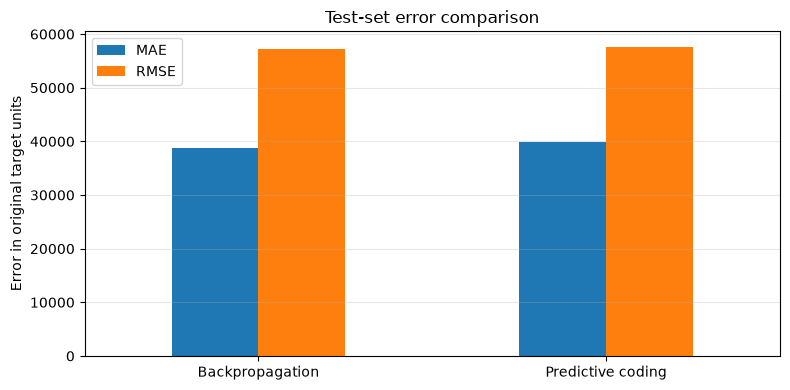

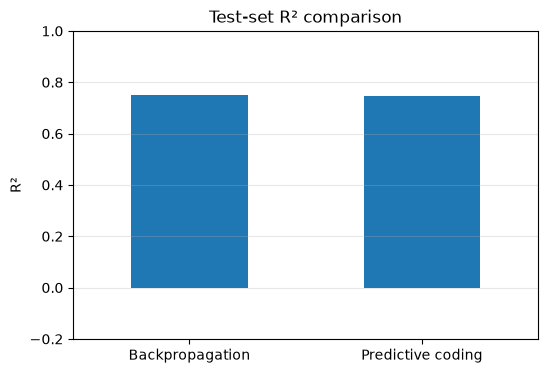

In [17]:
results = pd.DataFrame(
    [bp_metrics, pc_metrics],
    index=["Backpropagation", "Predictive coding"]
)
display(results.style.format({
    "MAE": "{:,.2f}",
    "RMSE": "{:,.2f}",
    "R2": "{:.4f}"
}))

ax = results[["MAE", "RMSE"]].plot(kind="bar", figsize=(8, 4))
ax.set_ylabel("Error in original target units")
ax.set_title("Test-set error comparison")
ax.tick_params(axis="x", rotation=0)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

results["R2"].plot(kind="bar", figsize=(6, 4), ylim=(-0.2, 1.0), title="Test-set R² comparison")
plt.ylabel("R²")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.show()

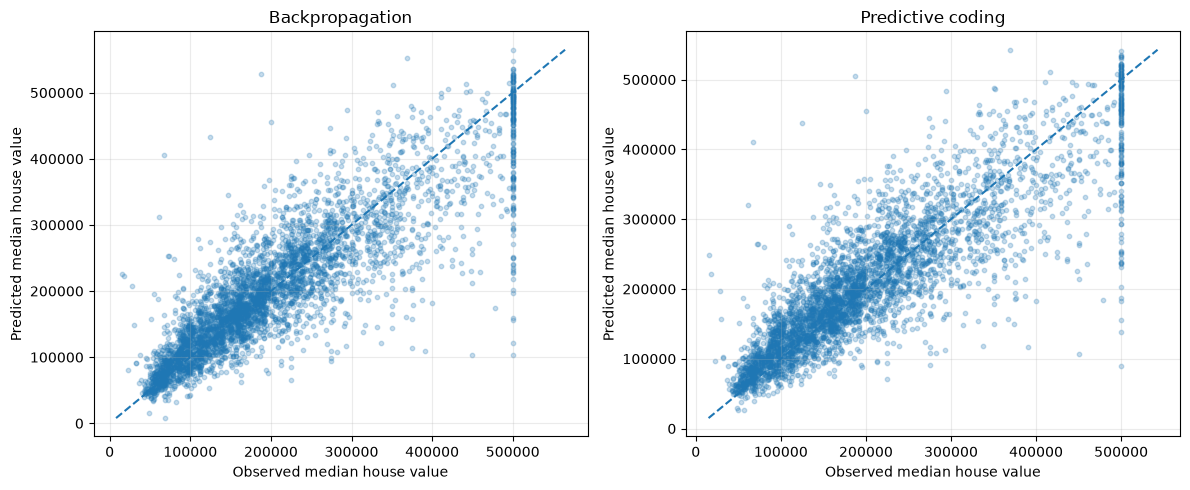

In [18]:
# Predicted versus observed values help reveal systematic bias and outliers.
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, pred, title in [
    (axes[0], bp_pred_original, "Backpropagation"),
    (axes[1], pc_pred_original, "Predictive coding")
]:
    ax.scatter(y_test_raw.to_numpy(), pred, alpha=0.25, s=10)
    low = min(y_test_raw.min(), np.min(pred))
    high = max(y_test_raw.max(), np.max(pred))
    ax.plot([low, high], [low, high], linestyle="--")
    ax.set_xlabel("Observed median house value")
    ax.set_ylabel("Predicted median house value")
    ax.set_title(title)
    ax.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()

In [20]:
from pathlib import Path
import json
import pickle
artifact_dir = Path("artifacts/house_value_regression")
artifact_dir.mkdir(parents=True, exist_ok=True)


def save_checkpoint(model, filename, architecture, inference_steps=None):
    torch.save(
        {
            "architecture": architecture,
            "input_dim": int(input_dim),
            "hidden1": 64,
            "hidden2": 32,
            "target_mean": y_mean,
            "target_std": y_std,
            "inference_steps": inference_steps,
            "model_state_dict": {
                name: tensor.detach().cpu()
                for name, tensor in model.state_dict().items()
            },
        },
        artifact_dir / filename,
    )


save_checkpoint(bp_model, "backprop_model.pt", "BackpropRegressor")
save_checkpoint(
    pc_model, "predictive_coding_model.pt", "PredictiveCodingRegressor",
    inference_steps=selected_inference_steps
)

# Preserve the fitted imputation, encoding, and scaling pipeline.
with (artifact_dir / "preprocessor.pkl").open("wb") as file:
    pickle.dump(preprocessor, file)

# Save evaluation results and information needed to interpret/reload the models.
metadata = {
    "target": "median_house_value",
    "target_mean": y_mean,
    "target_std": y_std,
    "input_dim": int(input_dim),
    "seed": SEED,
    "predictive_coding_inference_steps": selected_inference_steps,
    "feature_names": preprocessor.get_feature_names_out().tolist(),
    "inference_step_validation": [
        {
            "inference_steps": int(record["Inference steps"]),
            "validation_mae": float(record["Validation MAE"]),
            "validation_rmse": float(record["Validation RMSE"]),
            "validation_r2": float(record["Validation R2"]),
            "training_seconds": float(record["20-epoch training seconds"])
        }
        for record in sweep_records
    ],
    "metrics": {
        "backprop": {name: float(value) for name, value in bp_metrics.items()},
        "predictive_coding": {name: float(value) for name, value in pc_metrics.items()},
    },
}
with (artifact_dir / "metadata.json").open("w", encoding="utf-8") as file:
    json.dump(metadata, file, indent=2, allow_nan=False)

# Save held-out predictions for later inspection.
pd.DataFrame(
    {
        "actual": y_test_raw.to_numpy().reshape(-1),
        "backprop_prediction": bp_pred_original.reshape(-1),
        "predictive_coding_prediction": pc_pred_original.reshape(-1),
    }
).to_csv(artifact_dir / "test_predictions.csv", index=False)

# Save training objectives and predictive-coding layer energies.
history = pd.DataFrame({
    "backprop_train_mse": pd.Series(bp_history),
    "predictive_coding_train_energy": pd.Series(pc_history),
})
history.index = range(1, len(history) + 1)
history.index.name = "epoch"
history.to_csv(artifact_dir / "training_history.csv")

energy_history = pd.DataFrame(
    pc_energy_history, columns=["E1", "E2", "E3"]
)
energy_history.index = range(1, len(energy_history) + 1)
energy_history.index.name = "epoch"
energy_history.to_csv(artifact_dir / "predictive_coding_layer_energies.csv")

# Save a combined plot of the training curves.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(bp_history, label="Backprop train MSE")
axes[0].plot(pc_history, label="Predictive-coding train energy")
axes[0].set(title="Training objectives", xlabel="Epoch", ylabel="Objective")
axes[0].legend()

for index, label in enumerate(("E1", "E2", "E3")):
    axes[1].plot(pc_energy_history[:, index], label=label)
axes[1].set(title="Predictive-coding layer energies", xlabel="Epoch", ylabel="Energy")
axes[1].legend()

fig.tight_layout()
fig.savefig(artifact_dir / "training_curves.png", dpi=160, bbox_inches="tight")
plt.close(fig)

print(f"Saved models and artifacts to: {artifact_dir.resolve()}")

Saved models and artifacts to: /home/solomon/Desktop/backprop-pc/notebooks/artifacts/house_value_regression


In [21]:
checkpoint = torch.load(
    artifact_dir / "backprop_model.pt",
    map_location=DEVICE,
    weights_only=True,
)
loaded_model = BackpropRegressor(
    checkpoint["input_dim"],
    hidden1=checkpoint["hidden1"],
    hidden2=checkpoint["hidden2"],
).to(DEVICE)
loaded_model.load_state_dict(checkpoint["model_state_dict"])
loaded_model.eval()

BackpropRegressor(
  (layers): Sequential(
    (0): Linear(in_features=13, out_features=64, bias=True)
    (1): Tanh()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): Tanh()
    (4): Linear(in_features=32, out_features=1, bias=True)
  )
)

## 15. How I interpret the results

I use the measured results rather than assuming either method must win. If the backpropagation model has lower test error, that tells me its optimization and architecture generalized better on this split. If the predictive-coding model is competitive or better on some metrics, that suggests the iterative inference process and the energy-based objective may provide a useful inductive bias on this task.

The comparison is empirical:

$$
\text{winner} := \arg\min_{m \in \{\text{BP}, \text{PC}\}} \text{RMSE}_m
$$

and the notebook treats model quality as a measured outcome rather than a theoretical assumption. I keep the evaluation conditions aligned so that the comparison is informative.


## 16. Which limitations of backpropagation I explore through predictive coding

The material raises concerns about standard backpropagation, including a backward error pathway, globally propagated error signals, and the need for a differentiable computational graph. In contrast, predictive coding replaces the single global gradient computation with iterative local consistency updates. The underlying optimization problem is still to minimize a discrepancy between predicted and observed quantities, but the path to the solution is different:

$$
\theta^* = \arg\min_{\theta} \mathcal{L}(\theta; D_{\text{train}})
$$

for backpropagation, versus energy minimization over latent states in predictive coding. This notebook is not trying to claim that one method is universally superior; it is examining how a different inference rule affects learning and representation under the same regression task.


## 17. Limitations I keep in mind

- I use one train/test split and one architecture for each method.
- Regression metrics can vary with random initialization and the chosen seed.
- The predictive-coding objective depends on the inference-step count and on the energy formulation.
- The results are intended as a comparative study, not as a universal claim about the best model for all tabular regression problems.

A careful notebook makes these caveats explicit, because the empirical question is not whether one method is mathematically "best" in the abstract; it is whether it performs well on this dataset under these assumptions.


## Run summary

This notebook runs as a small regression benchmark comparing a standard backpropagation network against a predictive-coding model on the California housing dataset. It downloads the data, selects `median_house_value` as the target, splits the data into train and test partitions, and applies preprocessing only on the training set so the evaluation remains fair.

The workflow then trains both models on the same transformed data, records the training objective and validation metrics, and compares their predictions on the held-out set using MAE, RMSE, and $R^2$. The predictive-coding variant also sweeps over several latent inference-step counts, selecting the value that minimizes validation RMSE before the final comparison.

The notebook saves the fitted preprocessing pipeline, model checkpoints, metadata, held-out predictions, training histories, layer-energy traces, and the final training-curve figure under `artifacts/house_value_regression`. This makes the run reproducible and lets later analysis reload the models and inspect their behavior without retraining.

The main technical fix in the run was a key mismatch in the saved validation sweep records: the notebook originally read `"Training seconds"` while the sweep dictionary stored `"20-epoch training seconds"`. After correcting that mismatch, the metadata export and artifact-generation section run consistently.

Overall, the notebook is structured as a fair empirical comparison: the same dataset, the same target, the same preprocessing pipeline, and the same evaluation metrics are used for both architectures. The conclusion is therefore not theoretical but data-driven: the notebook is designed to answer which optimization and inference scheme generalizes better under this specific regression task.
